## **Actividad | Dataset - Notebook**

## **Paso 1: Carga y descripcion del dataset**

Para esta actividad se utilizó el dataset AI4I 2020 Predictive Maintenance Dataset del UCI Machine Learning Repository. Este conjunto de datos contiene información relacionada con las condiciones de operación de maquinaria industrial y fue diseñado
para el desarrollo y evaluación de modelos de mantenimiento predictivo.

El dataset contiene 10,000 registros correspondientes a observaciones de operación
de las máquinas. Entre las variables disponibles se encuentran el tipo de producto,
temperatura del aire, temperatura del proceso, velocidad de rotación, torque y desgaste
de herramienta.

También se incluyen variables relacionadas con la ocurrencia de fallas. Para este
proyecto se utilizará Machine failure como variable objetivo, planteando el problema
como una tarea de clasificación binaria:

- **0:** No ocurrió una falla.
- **1:** Ocurrió una falla.

Las variables que identifican directamente tipos específicos de falla serán analizadas,
pero no se utilizarán posteriormente como características predictoras del modelo para
evitar introducir información directamente relacionada con la variable objetivo.

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import mlflow
import mlflow.sklearn
import os

In [2]:
# Cargar el dataset
ai4i = fetch_ucirepo(id=601)

# Separar características (X) y variables objetivo (y)
X = ai4i.data.features
y = ai4i.data.targets

# Dimensiones del dataset
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print(f"\nNúmero de registros: {X.shape[0]}")
print(f"Número de características: {X.shape[1]}")
print(f"Número de variables objetivo: {y.shape[1]}")

# Información general y tipos de datos
print("\n--- INFORMACIÓN DE LAS CARACTERÍSTICAS ---")
X.info()

print("\n--- TIPOS DE LAS VARIABLES OBJETIVO ---")
print(y.dtypes)

# Información de las variables proporcionada por UCI
print("\n--- DESCRIPCIÓN DE LAS VARIABLES ---")
display(ai4i.variables)

# Combinar características y variables objetivo
df = pd.concat([X, y], axis=1)
print("\nDimensiones del DataFrame completo:", df.shape)

# Visualizar los primeros registros
print("\n--- PRIMEROS REGISTROS ---")
display(df.head())

# Metadata del dataset
print("\n--- METADATA DEL DATASET ---")
print(ai4i.metadata)

Dimensiones de X: (10000, 6)
Dimensiones de y: (10000, 6)

Número de registros: 10000
Número de características: 6
Número de variables objetivo: 6

--- INFORMACIÓN DE LAS CARACTERÍSTICAS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Type                 10000 non-null  object 
 1   Air temperature      10000 non-null  float64
 2   Process temperature  10000 non-null  float64
 3   Rotational speed     10000 non-null  int64  
 4   Torque               10000 non-null  float64
 5   Tool wear            10000 non-null  int64  
dtypes: float64(3), int64(2), object(1)
memory usage: 468.9+ KB

--- TIPOS DE LAS VARIABLES OBJETIVO ---
Machine failure    int64
TWF                int64
HDF                int64
PWF                int64
OSF                int64
RNF                int64
dtype: object

--- DESCRIPCIÓN DE LAS VARIABLES

,name,role,type,demographic,description,units,missing_values
0,UID,ID,Integer,None,None,None,no
1,Product ID,ID,Categorical,None,None,None,no
2,Type,Feature,Categorical,None,None,None,no
3,Air temperature,Feature,Continuous,None,None,K,no
4,Process temperature,Feature,Continuous,None,None,K,no
5,Rotational speed,Feature,Integer,None,None,rpm,no
6,Torque,Feature,Continuous,None,None,Nm,no
7,Tool wear,Feature,Integer,None,None,min,no
8,Machine failure,Target,Integer,None,None,None,no
9,TWF,Target,Integer,None,None,None,no



Dimensiones del DataFrame completo: (10000, 12)

--- PRIMEROS REGISTROS ---


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



--- METADATA DEL DATASET ---
{'uci_id': 601, 'name': 'AI4I 2020 Predictive Maintenance Dataset', 'repository_url': 'https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/601/data.csv', 'abstract': 'The AI4I 2020 Predictive Maintenance Dataset is a synthetic dataset that reflects real predictive maintenance data encountered in industry.', 'area': 'Computer Science', 'tasks': ['Classification', 'Regression', 'Causal-Discovery'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 10000, 'num_features': 6, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'], 'index_col': ['UID', 'Product ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Wed Feb 14 2024', 'dataset_doi': '10.24432/C5HS5C', 'creators': [], 'intro_paper': {'ID': 386, 'type': 'NATIVE', 'title': 'Exp

## **Paso 2. Análisis exploratorio de datos (EDA)**

Se realizó un análisis exploratorio para comprender la distribución de las variables y las relaciones existentes entre ellas. Primero se calcularon estadísticas descriptivas de las variables numéricas, incluyendo media, desviación estándar, valores mínimos, máximos y cuartiles.

Posteriormente se analizó la distribución de la variable objetivo `Machine failure` para determinar la proporción de observaciones correspondientes a operaciones normales y fallas. También se generaron histogramas para analizar la distribución de las principales variables operativas y diagramas de caja para identificar posibles valores atípicos.

Finalmente, se compararon las variables operativas entre los registros con y sin falla y se calculó una matriz de correlación para identificar relaciones entre las variables del dataset.

--- ESTADÍSTICAS DESCRIPTIVAS ---


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


--- DISTRIBUCIÓN DE MACHINE FAILURE ---
Machine failure
0    9661
1     339
Name: count, dtype: int64

Porcentaje:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


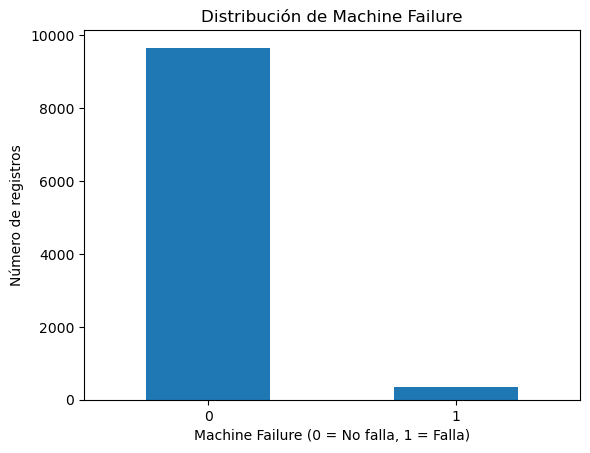

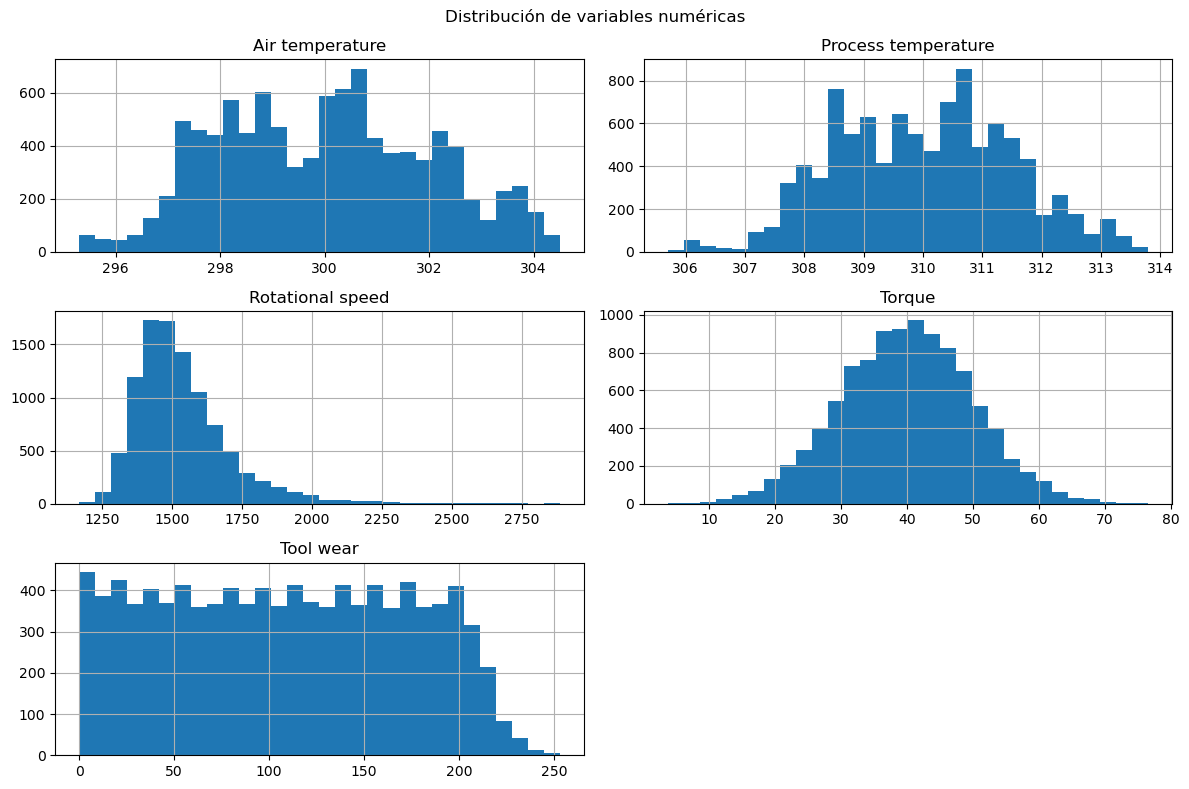

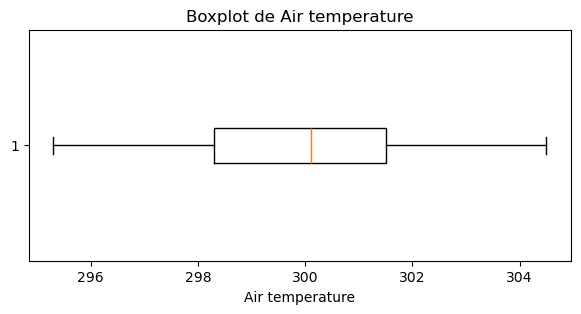

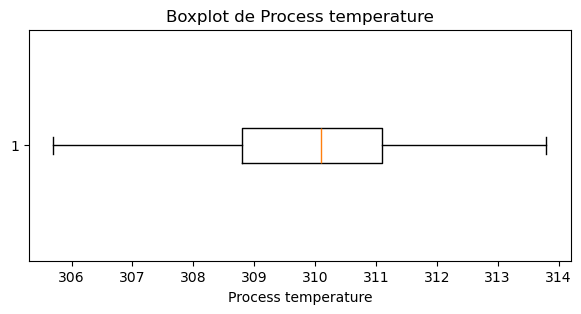

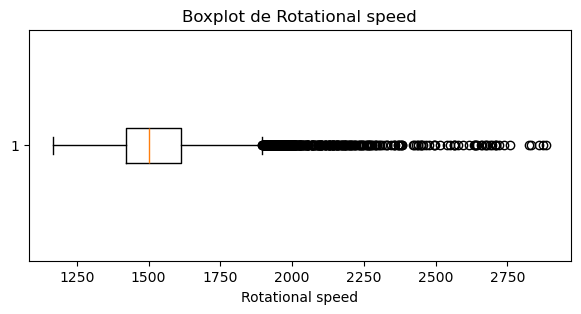

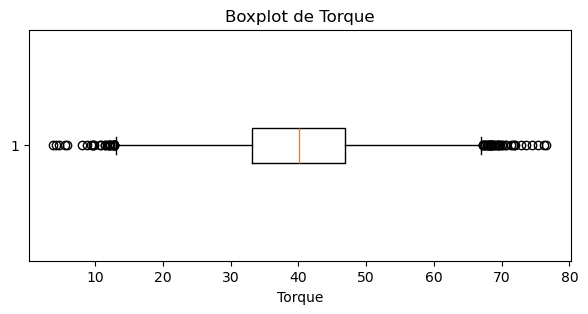

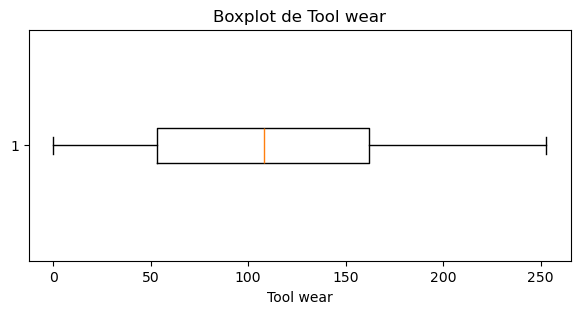

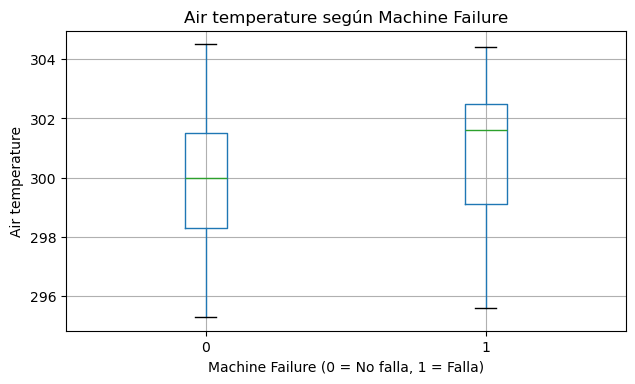

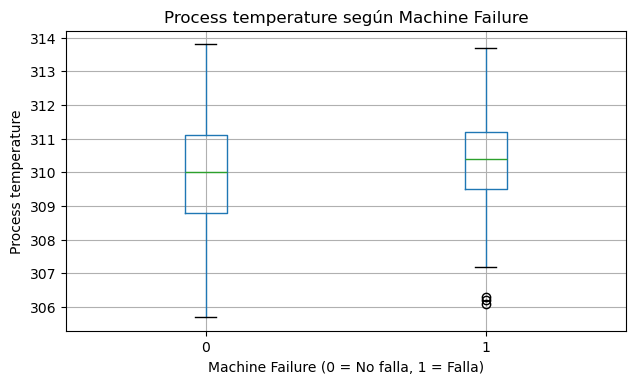

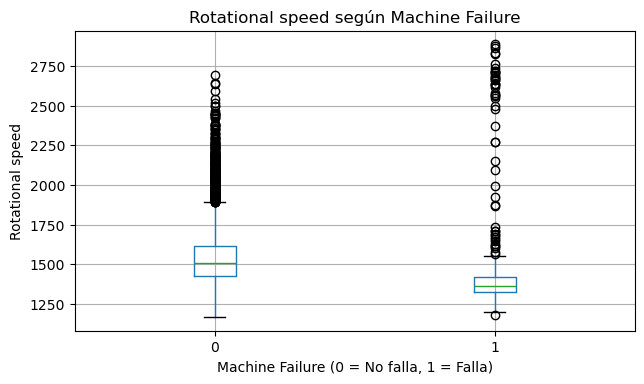

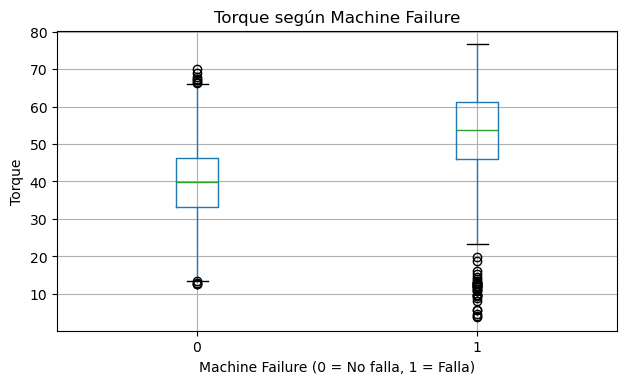

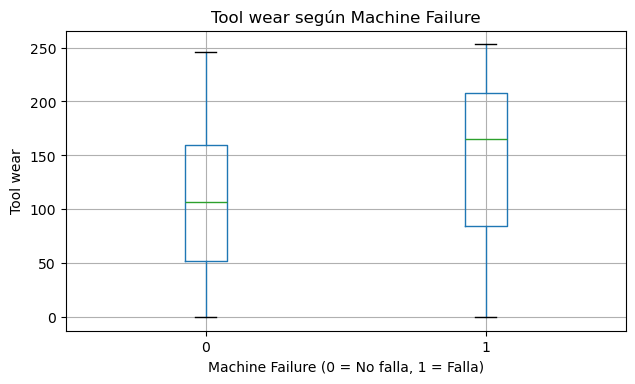

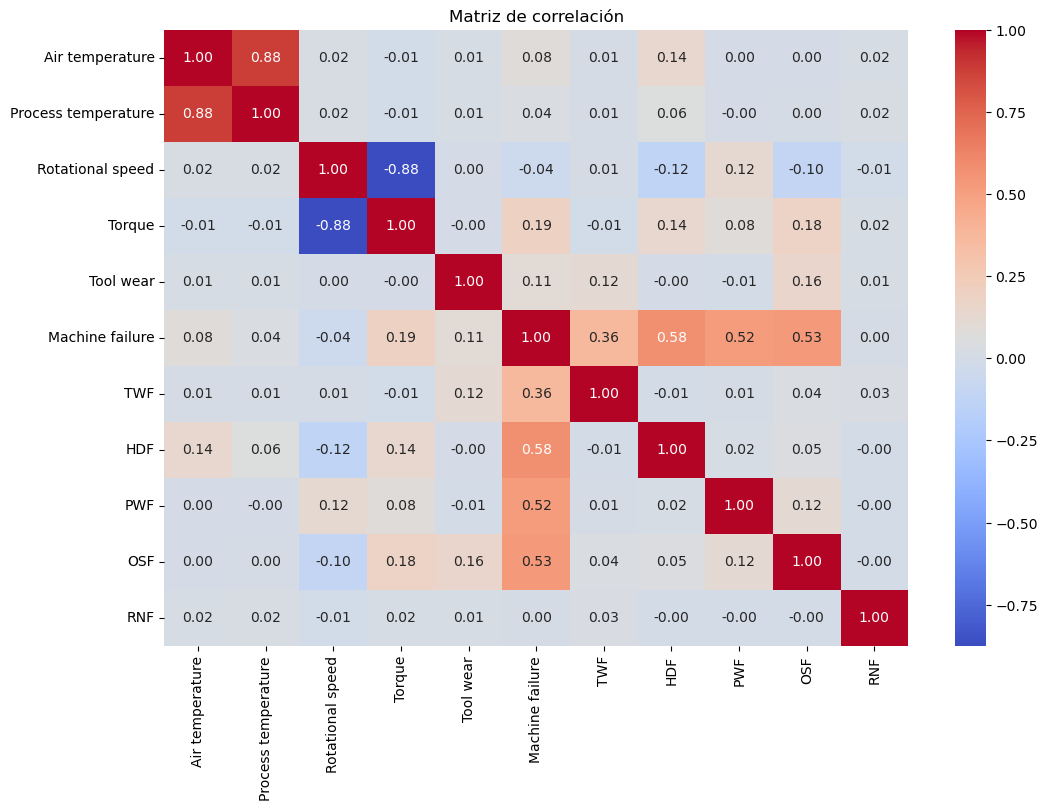

In [3]:
# Estadísticas descriptivas
print("--- ESTADÍSTICAS DESCRIPTIVAS ---")
display(df.describe())

# Distribución de la variable objetivo
print("--- DISTRIBUCIÓN DE MACHINE FAILURE ---")
print(df["Machine failure"].value_counts())
print("\nPorcentaje:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

df["Machine failure"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribución de Machine Failure")
plt.xlabel("Machine Failure (0 = No falla, 1 = Falla)")
plt.ylabel("Número de registros")
plt.xticks(rotation=0)
plt.show()

# Distribución de las variables numericas
variables_numericas = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

df[variables_numericas].hist(figsize=(12, 8), bins=30)
plt.suptitle("Distribución de variables numéricas")
plt.tight_layout()
plt.show()

# Boxplots
for columna in variables_numericas:
    plt.figure(figsize=(7, 3))
    plt.boxplot(df[columna].dropna(), vert=False)
    plt.title(f"Boxplot de {columna}")
    plt.xlabel(columna)
    plt.show()

# Comparar variables
for columna in variables_numericas:
    df.boxplot(column=columna, by="Machine failure", figsize=(7, 4))
    plt.title(f"{columna} según Machine Failure")
    plt.suptitle("")
    plt.xlabel("Machine Failure (0 = No falla, 1 = Falla)")
    plt.ylabel(columna)
    plt.show()

# Matriz de correlacion
df_numerico = df.select_dtypes(include=["number"])
correlacion = df_numerico.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Matriz de correlación")
plt.show()

El análisis de correlación muestra algunas relaciones importantes entre las variables del dataset.
Las variables `Air temperature` y `Process temperature` presentan una correlación positiva alta
de aproximadamente 0.88, lo que indica que ambas temperaturas tienden a aumentar o disminuir
de manera conjunta.

También se observa una correlación negativa alta (-0.88) entre `Rotational speed` y `Torque`.
Esto indica que, en las condiciones registradas, velocidades de rotación mayores suelen estar
asociadas con valores menores de torque.

Respecto a la variable objetivo `Machine failure`, las variables operativas presentan
correlaciones relativamente bajas. Entre ellas, `Torque` presenta la mayor correlación positiva
(0.19), seguida de `Tool wear` (0.11) y `Air temperature` (0.08). Esto sugiere que ninguna
variable operativa individual explica por sí sola la ocurrencia de una falla.

Por otro lado, las variables que representan tipos específicos de falla presentan correlaciones
considerablemente mayores con `Machine failure`, especialmente `HDF` (0.58), `OSF` (0.53) y
`PWF` (0.52). Debido a que estas variables indican directamente la ocurrencia de tipos de falla,
no se utilizarán posteriormente como variables predictoras del modelo, ya que esto podría
introducir fuga de información (data leakage).

## **Paso 3. Limpieza de los datos**

In [4]:
# Revisar valores faltantes
print("--- VALORES FALTANTES ---")
print(df.isnull().sum())
print("Total de valores faltantes:", df.isnull().sum().sum())

# Revisar registros duplicados
duplicados = df.duplicated().sum()
print("\n--- REGISTROS DUPLICADOS ---")
print("Número de registros duplicados:", duplicados)

# Outliers
print("\n--- OUTLIERS Y FALLAS ---")

variables_numericas = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

for columna in variables_numericas:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    outliers = df[
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    ]

    if len(outliers) > 0:
        porcentaje_fallas = outliers["Machine failure"].mean() * 100
        print(
            f"{columna}: {len(outliers)} outliers - "
            f"{porcentaje_fallas:.2f}% presentan Machine failure"
        )

# Características para el modelo
# X ya contiene únicamente las variables predictoras
X_clean = X.copy()

# Utilizar únicamente Machine failure como variable objetivo
y_clean = y["Machine failure"].copy()

print("\n--- DATOS PREPARADOS PARA EL MODELO ---")
print("Dimensiones de X_clean:", X_clean.shape)
print("Dimensiones de y_clean:", y_clean.shape)

display(X_clean.head())

--- VALORES FALTANTES ---
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Machine failure        0
TWF                    0
HDF                    0
PWF                    0
OSF                    0
RNF                    0
dtype: int64
Total de valores faltantes: 0

--- REGISTROS DUPLICADOS ---
Número de registros duplicados: 0

--- OUTLIERS Y FALLAS ---
Rotational speed: 418 outliers - 8.37% presentan Machine failure
Torque: 69 outliers - 89.86% presentan Machine failure

--- DATOS PREPARADOS PARA EL MODELO ---
Dimensiones de X_clean: (10000, 6)
Dimensiones de y_clean: (10000,)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


Se realizó una revisión de valores faltantes, registros duplicados y posibles valores atípicos. No se encontraron valores faltantes ni registros duplicados, por lo que no fue necesario eliminar registros ni realizar técnicas de imputación.

Para identificar posibles valores atípicos se utilizó el método del rango intercuartílico (IQR). Se identificaron 418 posibles outliers en `Rotational speed`, de los cuales 8.37% corresponden a registros con falla. También se encontraron 69 outliers en `Torque`, y 89.86% de ellos corresponden a registros con `Machine failure`.

Se decidió conservar estos valores atípicos debido a que pueden representar condiciones anormales de operación relevantes para la detección de fallas. En particular, la alta proporción de fallas encontrada entre los valores atípicos de torque indica que eliminarlos podría provocar la pérdida de información importante para el modelo.

Finalmente, se seleccionó `Machine failure` como única variable objetivo. Las variables TWF, HDF, PWF, OSF y RNF corresponden a tipos específicos de falla y no se utilizarán como predictores, evitando así una posible fuga de información (data leakage).

## **Paso 4. Entrenamiento del modelo base**

In [5]:
#Dividir 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

print("--- DIVISIÓN DEL DATASET ---")
print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])
print("\nDistribución de clases en entrenamiento:")
print(y_train.value_counts())
print("\nDistribución de clases en prueba:")
print(y_test.value_counts())

variables_numericas = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

variables_categoricas = ["Type"]

# Crear el preprocesamiento
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), variables_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), variables_categoricas)
    ]
)

# Crear el modelo base
modelo_base = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Crear el Pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", modelo_base)
    ]
)

# Entrenar el modelo
pipeline.fit(X_train, y_train)

# Generar predicciones
y_pred = pipeline.predict(X_test)
print("\nPredicciones generadas:", len(y_pred))
print("Primeras 20 predicciones:")
print(y_pred[:20])

--- DIVISIÓN DEL DATASET ---
Registros de entrenamiento: 8000
Registros de prueba: 2000

Distribución de clases en entrenamiento:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Distribución de clases en prueba:
Machine failure
0    1932
1      68
Name: count, dtype: int64

Predicciones generadas: 2000
Primeras 20 predicciones:
[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


Se seleccionó una Regresión Logística como modelo baseline debido a que el problema consiste
en una clasificación binaria, donde la variable objetivo `Machine failure` indica si ocurrió
o no una falla.

El conjunto de datos se dividió en 80% para entrenamiento y 20% para prueba. Se utilizó una
división estratificada para conservar aproximadamente la misma proporción de fallas en ambos
conjuntos, debido al desbalance existente en la variable objetivo.

Antes del entrenamiento, las variables numéricas fueron estandarizadas mediante
`StandardScaler`, mientras que la variable categórica `Type` fue transformada mediante
`OneHotEncoder`.

El preprocesamiento y la regresión logística se integraron utilizando un `Pipeline` de
Scikit-learn. De esta manera, las transformaciones se ajustan únicamente utilizando los datos
de entrenamiento, evitando que información del conjunto de prueba influya en el entrenamiento
del modelo.

## **Paso 5: Evaluación del modelo**

--- MÉTRICAS DEL MODELO BASE ---
Accuracy:  0.9675
Precision: 0.6364
Recall:    0.1029
F1-score:  0.1772

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

    No falla       0.97      1.00      0.98      1932
       Falla       0.64      0.10      0.18        68

    accuracy                           0.97      2000
   macro avg       0.80      0.55      0.58      2000
weighted avg       0.96      0.97      0.96      2000


--- MATRIZ DE CONFUSIÓN ---
[[1928    4]
 [  61    7]]


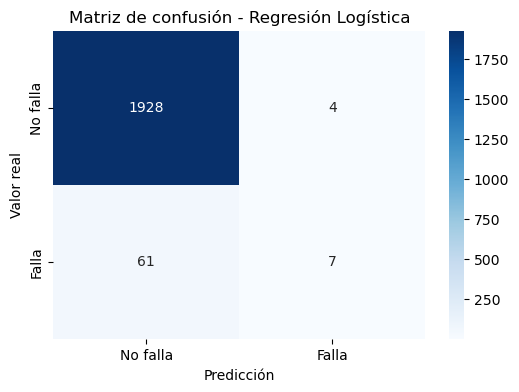


--- COMPARACIÓN CON BASELINE TRIVIAL ---
Accuracy prediciendo siempre 'No falla': 0.9660
Accuracy de la Regresión Logística:       0.9675


In [6]:
# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
print("--- MÉTRICAS DEL MODELO BASE ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# Reporte de clasificacion
print("\n--- CLASSIFICATION REPORT ---")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No falla", "Falla"],
        zero_division=0
    )
)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
print("\n--- MATRIZ DE CONFUSIÓN ---")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No falla", "Falla"],
    yticklabels=["No falla", "Falla"]
)
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Regresión Logística")
plt.show()

# Comparación contra un modelo que siempre predice "No falla"
accuracy_trivial = (y_test == 0).mean()
print("\n--- COMPARACIÓN CON BASELINE TRIVIAL ---")
print(f"Accuracy prediciendo siempre 'No falla': {accuracy_trivial:.4f}")
print(f"Accuracy de la Regresión Logística:       {accuracy:.4f}")

El modelo de Regresión Logística obtuvo un accuracy de 96.75%. A primera vista este
resultado podría parecer muy bueno; sin embargo, la variable objetivo presenta un fuerte
desbalance, ya que solamente 68 de los 2,000 registros del conjunto de prueba corresponden
a fallas.

La matriz de confusión muestra que el modelo identificó correctamente 7 de las 68 fallas
reales, mientras que 61 fueron clasificadas incorrectamente como operaciones normales.
Esto se refleja en un recall de 10.29% para la clase de falla, lo que significa que el
modelo solamente logró detectar aproximadamente una de cada diez fallas.

La precisión para la clase de falla fue de 63.64%, indicando que, cuando el modelo predijo
una falla, la predicción fue correcta en aproximadamente el 64% de los casos. Sin embargo,
el bajo recall provocó un F1-score de solamente 17.72%.

Además, un modelo trivial que clasificara todos los registros como "No falla" alcanzaría
un accuracy de 96.60%, mientras que la Regresión Logística obtuvo 96.75%. Por lo tanto,
el alto accuracy se debe principalmente al fuerte desbalance de clases y no implica que
el modelo tenga una buena capacidad para detectar fallas.

En un escenario de mantenimiento predictivo, los falsos negativos son especialmente
importantes, ya que representan fallas reales que el modelo no detectó. Por esta razón,
el recall y el F1-score de la clase de falla proporcionan una evaluación más útil que
el accuracy para este problema.

## **Paso 6: Registrar el experimento en MLFlow**

In [15]:
# Nombre del experimento
mlflow.set_experiment("AI4I_Predictive_Maintenance")

with mlflow.start_run(run_name="Logistic_Regression_Baseline"):

    # Registrar parámetros
    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("stratify", True)
    mlflow.log_param("max_iter", 1000)

    # Registrar métricas
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)

    # Crear matriz de confusión
    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No falla", "Falla"],
        yticklabels=["No falla", "Falla"]
    )

    plt.xlabel("Predicción")
    plt.ylabel("Valor real")
    plt.title("Matriz de confusión - Regresión Logística")

    # Guardar y registrar matriz de confusión
    plt.savefig("matriz_confusion.png", bbox_inches="tight")
    plt.close()

    mlflow.log_artifact("matriz_confusion.png")

    # Registrar el pipeline utilizando cloudpickle
    mlflow.sklearn.log_model(
        pipeline,
        name="modelo_baseline",
        serialization_format="cloudpickle"
    )

2026/09/29 23:55:30 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [16]:
runs = mlflow.search_runs(
    experiment_names=["AI4I_Predictive_Maintenance"]
)

display(
    runs[
        [
            "run_id",
            "params.model",
            "metrics.accuracy",
            "metrics.precision",
            "metrics.recall",
            "metrics.f1_score"
        ]
    ]
)

,run_id,params.model,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score
0,cb1a16260b1747e5a0f028998de1a637,LogisticRegression,0.9675,0.636364,0.102941,0.177215


## **Paso 7. Reflexión**

A partir de este ejercicio pude observar que desarrollar un modelo de Machine Learning no consiste únicamente en entrenar un algoritmo y obtener una métrica de desempeño. Es necesario mantener un flujo organizado y reproducible desde la obtención y exploración de los datos hasta la evaluación y registro del experimento. En este caso, aunque la Regresión Logística obtuvo un accuracy de 96.75%, el análisis de otras métricas mostró que el modelo solamente detectó aproximadamente el 10% de las fallas reales. Esto demuestra la importancia de seleccionar métricas adecuadas según el problema y de considerar el desbalance de clases.

Como mejora al flujo, probaría técnicas para tratar este desbalance, como el uso de pesos de clase, y compararía diferentes algoritmos y configuraciones. También incorporaría prácticas de MLOps como versionamiento de datos y modelos, automatización de los pipelines de entrenamiento y evaluación, validaciones automáticas y monitoreo del desempeño del modelo una vez desplegado. MLflow permitiría conservar la trazabilidad de estos experimentos y comparar de manera organizada los resultados obtenidos.

Estos aprendizajes tienen una aplicación directa en mi área profesional de control y automatización industrial. En sistemas reales, los PLC y sistemas SCADA generan continuamente información de variables de proceso que puede almacenarse en un historian. Estos datos podrían utilizarse para desarrollar modelos de mantenimiento predictivo similares al trabajado en esta actividad. Un modelo podría analizar variables como temperatura, velocidad, torque, presión o vibración para detectar condiciones asociadas con posibles fallas. Sin embargo, para utilizar un modelo de este tipo en producción sería indispensable mantener control sobre las versiones, validar los datos de entrada, monitorear su desempeño y contar con un proceso reproducible para entrenarlo nuevamente cuando cambien las condiciones del proceso.

![Evidencia del experimento en MLflow](Evidencia1.png)